# YOLO26s + LoRA 独立正式微调

以已完成的 YOLO26s `best.pt` 为只读基座。正式产物只写入 `models/trained/yolo26_lora/formal/yolo26s_lora_formal/`，不会覆盖完整微调模型。请先确认冒烟 Notebook 全部通过。

In [1]:
from pathlib import Path
import hashlib, json, sys

PROJECT_ROOT = next(p for p in (Path.cwd().resolve(), *Path.cwd().resolve().parents) if (p / 'training').is_dir())
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))
print('Project:', PROJECT_ROOT)

Project: D:\dev\projects\yolo_train


In [2]:
import torch, ultralytics
from training.train_yolo26_lora import BASE_MODEL, train

print('Python:', sys.version.split()[0])
print('Ultralytics:', ultralytics.__version__, ultralytics.__file__)
print('CUDA:', torch.cuda.is_available())
print('GPU:', torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'CPU')
if '.venv-yolo26' not in str(Path(ultralytics.__file__).resolve()):
    raise RuntimeError('请切换到项目独立 YOLO26 Kernel，不能使用 YOLO-Master 环境')
if not BASE_MODEL.is_file() or not torch.cuda.is_available():
    raise RuntimeError('基座模型或 CUDA 不可用')
BASE_SHA256 = hashlib.sha256(BASE_MODEL.read_bytes()).hexdigest()
print('Protected baseline:', BASE_MODEL)
print('Baseline SHA256:', BASE_SHA256)

Python: 3.13.9
Ultralytics: 8.4.55 D:\dev\projects\yolo_train\.venv-yolo26\Lib\site-packages\ultralytics\__init__.py
CUDA: True
GPU: NVIDIA GeForce RTX 5060 Laptop GPU
Protected baseline: D:\dev\projects\yolo_train\models\trained\yolo26\formal\yolo26s_full_768_formal\weights\best.pt
Baseline SHA256: e2560d33b17df7e1d5c93cadeb80d9bba20434d0b76c9b55f4b25055461c1b47


## 正式训练

默认 rank=8、alpha=16，只训练约 2.15% 参数。已存在同名目录时会直接报错，防止覆盖；中断恢复时将 `resume=True`。

In [3]:
EPOCHS = 150
IMAGE_SIZE = 768
BATCH = 4
RANK = 8
ALPHA = 16.0
DROPOUT = 0.05
RUN_NAME = 'yolo26s_lora_formal'
RESUME = False

In [4]:
best = train(
    smoke=False, epochs=EPOCHS, batch=BATCH, imgsz=IMAGE_SIZE,
    rank=RANK, alpha=ALPHA, dropout=DROPOUT,
    run_name=RUN_NAME, resume=RESUME, export_onnx=True,
)
if hashlib.sha256(BASE_MODEL.read_bytes()).hexdigest() != BASE_SHA256:
    raise RuntimeError('受保护的 YOLO26s 基座发生变化')
print('Formal merged best:', best)

Ultralytics 8.4.55  Python-3.13.9 torch-2.13.0+cu132 CUDA:0 (NVIDIA GeForce RTX 5060 Laptop GPU, 8151MiB)
engine\trainer: agnostic_nms=False, amp=False, angle=1.0, augment=False, auto_augment=randaugment, batch=4, bgr=0.0, box=7.5, cache=False, cfg=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=D:\dev\projects\yolo_train\data\processed\data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dnn=False, dropout=0.0, dynamic=False, embed=None, end2end=None, epochs=150, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=[0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22], half=False, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=768, int8=False, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.0001, lrf=0.05, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=D:\dev\projects\yolo_train\models\trained

D:\dev\runtimes\conda\envs\yolo\Lib\site-packages\torch\onnx\_internal\torchscript_exporter\symbolic_opset11.py:954: UserWarning: Exporting aten::index operator of advanced indexing in opset 18 is achieved by combination of multiple ONNX operators, including Reshape, Transpose, Concat, and Gather. If indices include negative values, the exported graph will produce incorrect results.
  return opset9.index(g, self, index)


ONNX: slimming with onnxslim 0.1.94...
ONNX: export success  1.7s, saved as 'D:\dev\projects\yolo_train\models\trained\yolo26_lora\formal\yolo26s_lora_formal\weights\best.onnx' (36.5 MB)

Export complete (1.7s)
Results saved to D:\dev\projects\yolo_train\models\trained\yolo26_lora\formal\yolo26s_lora_formal\weights\best.onnx
Predict:         yolo predict task=detect model=D:\dev\projects\yolo_train\models\trained\yolo26_lora\formal\yolo26s_lora_formal\weights\best.onnx imgsz=768 
Validate:        yolo val task=detect model=D:\dev\projects\yolo_train\models\trained\yolo26_lora\formal\yolo26s_lora_formal\weights\best.onnx imgsz=768 data=D:\dev\projects\yolo_train\data\processed\data.yaml  
Visualize:       https://netron.app
Formal merged best: D:\dev\projects\yolo_train\models\trained\yolo26_lora\formal\yolo26s_lora_formal\weights\best.pt


In [5]:
RUN_DIR = best.parents[1]
manifest = json.loads((RUN_DIR / 'lora_manifest.json').read_text(encoding='utf-8'))
manifest

{'format': 'yolo26-conv-lora-v1',
 'smoke_only': False,
 'base_model': 'D:\\dev\\projects\\yolo_train\\models\\trained\\yolo26\\formal\\yolo26s_full_768_formal\\weights\\best.pt',
 'base_sha256': 'e2560d33b17df7e1d5c93cadeb80d9bba20434d0b76c9b55f4b25055461c1b47',
 'merged_best': 'D:\\dev\\projects\\yolo_train\\models\\trained\\yolo26_lora\\formal\\yolo26s_lora_formal\\weights\\best.pt',
 'lora_best': 'D:\\dev\\projects\\yolo_train\\models\\trained\\yolo26_lora\\formal\\yolo26s_lora_formal\\weights\\lora_best.pt',
 'adapter': 'D:\\dev\\projects\\yolo_train\\models\\trained\\yolo26_lora\\formal\\yolo26s_lora_formal\\adapters\\adapter.pt',
 'config': {'rank': 8,
  'alpha': 16.0,
  'dropout': 0.05,
  'min_layer': 10,
  'max_layer': 22,
  'min_channels': 32,
  'exclude_attention': True},
 'target_count': 39,
 'merge_max_abs_error': 6.103515625e-05,
 'fixed_test': {'precision': 0.9231955153403573,
  'recall': 0.8352655028656418,
  'map50': 0.9183322761664,
  'map50_95': 0.8532788829914657},


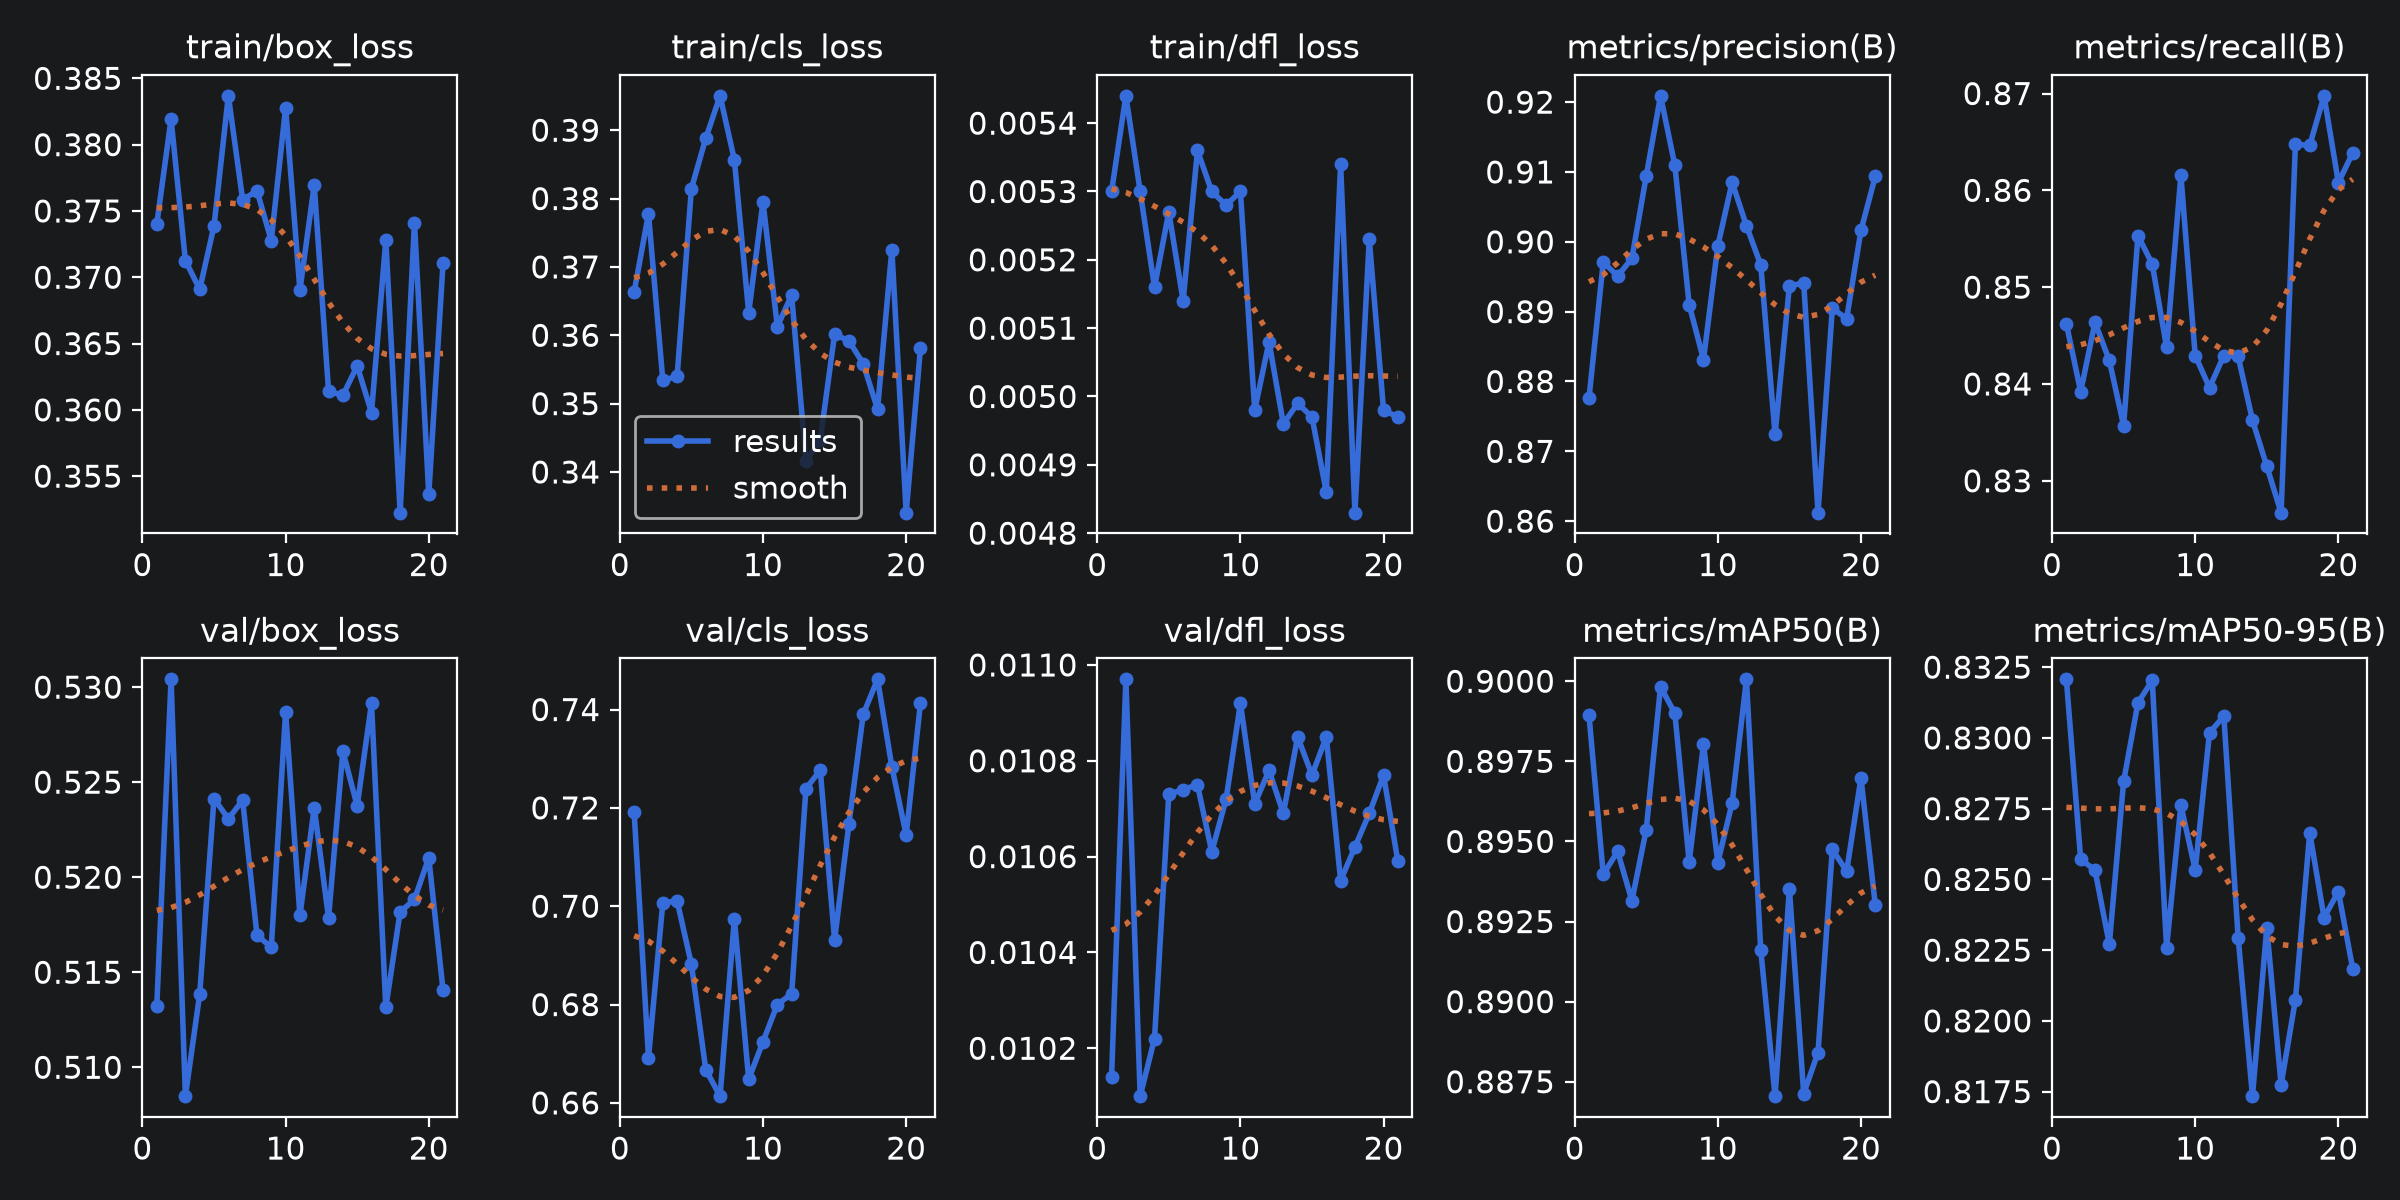

Adapter: D:\dev\projects\yolo_train\models\trained\yolo26_lora\formal\yolo26s_lora_formal\adapters\adapter.pt
Merged PT: D:\dev\projects\yolo_train\models\trained\yolo26_lora\formal\yolo26s_lora_formal\weights\best.pt
ONNX: D:\dev\projects\yolo_train\models\trained\yolo26_lora\formal\yolo26s_lora_formal\weights\best.onnx


In [6]:
from IPython.display import Image, display
curve = RUN_DIR / 'results.png'
if curve.is_file():
    display(Image(filename=str(curve)))
print('Adapter:', RUN_DIR / 'adapters/adapter.pt')
print('Merged PT:', best)
print('ONNX:', best.with_suffix('.onnx'))